
# E7 — Robustness, Statistical Inference, and Publication-Ready Synthesis

## Purpose

E7 is the **verification and synthesis layer** for E0–E6. It does not introduce a new prediction algorithm. Instead, it tests whether the principal conclusions remain stable under resampling, data-quality corrections, different capacity assumptions, and alternative conformal confidence levels.

## E7 components

1. **Bootstrap 95% confidence intervals** for key repeated-resampling results.
2. **Paired statistical comparisons** where observations are genuinely paired.
3. **Random-seed sensitivity** of the IID baseline.
4. **Capacity sensitivity** beyond the original 10–25% grid.
5. **Conformal alpha sensitivity** from 80% to 95% nominal coverage.
6. **Predictor-dominance ablation** centered on `Exam_Pressure`.
7. **Original vs plausibility-corrected data sensitivity**.
8. **Publication-ready consolidated tables and figures**.

## Statistical caution

Repeated folds/splits are not independent draws from a population. Therefore:
- bootstrap intervals summarize **resampling stability**, not population sampling uncertainty;
- Wilcoxon tests are used only for paired algorithmic comparisons on the same resampling units;
- LOSO comparisons with only three held-out populations are treated descriptively rather than as formal hypothesis tests.


In [1]:

from pathlib import Path
import platform, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    brier_score_loss, log_loss, recall_score,
    precision_recall_curve
)
from scipy.stats import wilcoxon

SEED = 42
RNG = np.random.default_rng(SEED)
TARGET = "Stress_Level"
GROUP = "Student_Type"

DATA_CANDIDATES = [
    Path("/mnt/data/student-lifestyle-and-stress-dataset.csv"),
    Path("student-lifestyle-and-stress-dataset.csv"),
    Path("../data/student-lifestyle-and-stress-dataset.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Place student-lifestyle-and-stress-dataset.csv beside this notebook, "
        "inside ../data, or edit DATA_PATH."
    )

RESULT_DIR = Path("../outputs/E7")
RESULT_DIR.mkdir(exist_ok=True)

E0_DIR = Path("../outputs/E0_E2")
E3_DIR = Path("../outputs/E3")
E4_DIR = Path("../outputs/E4")
E5_DIR = Path("../outputs/E5")
E6_DIR = Path("../outputs/E6")

required_dirs = [E0_DIR, E3_DIR, E4_DIR, E5_DIR, E6_DIR]
missing_dirs = [str(p) for p in required_dirs if not p.exists()]
if missing_dirs:
    raise FileNotFoundError(
        "E7 expects E0–E6 outputs in the same working directory. "
        f"Missing: {missing_dirs}. Run E0–E6 first, or use the combined master notebook."
    )

df = pd.read_csv(DATA_PATH)

print("Python :", platform.python_version())
print("pandas :", pd.__version__)
print("sklearn:", sklearn.__version__)
print("Dataset:", DATA_PATH.resolve())
print("Rows   :", len(df))


Python : 3.13.5
pandas : 2.2.3
sklearn: 1.8.0
Dataset: /mnt/data/student-lifestyle-and-stress-dataset.csv
Rows   : 25500


# Common helpers

In [2]:

NUMERIC_FEATURES = [
    "Sleep_Hours", "Study_Hours", "Social_Media_Hours",
    "Attendance", "Exam_Pressure", "Family_Support"
]
FULL_GROUPBLIND = NUMERIC_FEATURES + ["Month"]

def make_lr_pipeline(features):
    numeric = [c for c in features if c in NUMERIC_FEATURES]
    categorical = [c for c in features if c == "Month"]

    transformers = []
    if numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric,
        ))
    if categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            categorical,
        ))

    prep = ColumnTransformer(transformers, sparse_threshold=0)
    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            max_iter=2000, solver="lbfgs", random_state=SEED
        )),
    ])

def bootstrap_mean_ci(values, n_boot=5000, seed=SEED):
    x = np.asarray(pd.Series(values).dropna(), dtype=float)
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(axis=1)
    return (
        float(x.mean()),
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )

def paired_bootstrap_diff(a, b, n_boot=5000, seed=SEED):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    d = a[mask] - b[mask]
    if len(d) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    means = d[idx].mean(axis=1)
    return (
        float(d.mean()),
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )

def safe_wilcoxon(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    a, b = a[mask], b[mask]
    if len(a) < 5 or np.allclose(a, b):
        return np.nan, np.nan, len(a)
    try:
        stat, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
        return float(stat), float(p), len(a)
    except ValueError:
        return np.nan, np.nan, len(a)

def binary_metrics(y, p):
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    pred = (p >= 0.5).astype(int)
    return {
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "nll": log_loss(y, p, labels=[0, 1]),
        "recall": recall_score(y, pred, zero_division=0),
    }

def joint_strata(frame):
    return (
        frame[GROUP].astype(str)
        + "__Y" + frame[TARGET].astype(int).astype(str)
    )

def select_recall_threshold(y, p, target_recall=0.80):
    precision, recall, thresholds = precision_recall_curve(y, p)
    if len(thresholds) == 0:
        return 0.5
    valid = recall[:-1] >= target_recall
    if not np.any(valid):
        return 0.0
    return float(np.max(thresholds[valid]))


# E7.1 — Bootstrap CIs and paired comparisons

In [3]:

# --- E3 paired calibration comparisons across the same IID outer folds ---
e3 = pd.read_csv(E3_DIR / "e3_iid_fold_metrics.csv")

pair_rows = []
for comparator in ["sigmoid", "isotonic"]:
    for metric in [
        "brier", "nll", "ece_uniform", "ece_quantile",
        "mce_uniform", "mce_quantile"
    ]:
        base = (
            e3[e3["method"] == "uncalibrated"]
            .sort_values(["repeat", "fold"])
        )
        comp = (
            e3[e3["method"] == comparator]
            .sort_values(["repeat", "fold"])
        )

        # Improvement convention:
        # positive => comparator has lower error than uncalibrated.
        diff_mean, ci_lo, ci_hi = paired_bootstrap_diff(
            base[metric].to_numpy(),
            comp[metric].to_numpy(),
            seed=SEED + hash(metric + comparator) % 10000,
        )
        stat, pval, n_pair = safe_wilcoxon(
            base[metric].to_numpy(),
            comp[metric].to_numpy(),
        )
        pair_rows.append({
            "experiment": "E3",
            "comparison": f"{comparator}_vs_uncalibrated",
            "metric": metric,
            "paired_n": n_pair,
            "mean_improvement": diff_mean,
            "bootstrap95_low": ci_lo,
            "bootstrap95_high": ci_hi,
            "wilcoxon_stat": stat,
            "wilcoxon_p": pval,
        })

# --- E5 paired Mondrian vs marginal across heldout × repeat ---
e5 = pd.read_csv(E5_DIR / "e5_conformal_metrics_by_repeat.csv")
e5t = e5[e5["domain"] == "target_loso"].copy()

for alpha in sorted(e5t["alpha"].unique()):
    for metric in [
        "marginal_coverage",
        "coverage_high",
        "decision_coverage",
        "selective_accuracy",
        "actionable_high_stress_recall",
        "false_negative_singleton_rate",
    ]:
        left = (
            e5t[
                (e5t["alpha"] == alpha) &
                (e5t["method"] == "mondrian")
            ]
            .sort_values(["heldout_group", "repeat"])
        )
        right = (
            e5t[
                (e5t["alpha"] == alpha) &
                (e5t["method"] == "marginal")
            ]
            .sort_values(["heldout_group", "repeat"])
        )

        # For false-negative singleton rate, lower is better; flip sign.
        if metric == "false_negative_singleton_rate":
            a, b = right[metric].to_numpy(), left[metric].to_numpy()
            label = "marginal_minus_mondrian"
        else:
            a, b = left[metric].to_numpy(), right[metric].to_numpy()
            label = "mondrian_minus_marginal"

        diff_mean, ci_lo, ci_hi = paired_bootstrap_diff(
            a, b, seed=SEED + int(alpha*1000) + len(metric)
        )
        stat, pval, n_pair = safe_wilcoxon(a, b)
        pair_rows.append({
            "experiment": "E5",
            "comparison": f"{label}_alpha_{alpha}",
            "metric": metric,
            "paired_n": n_pair,
            "mean_improvement": diff_mean,
            "bootstrap95_low": ci_lo,
            "bootstrap95_high": ci_hi,
            "wilcoxon_stat": stat,
            "wilcoxon_p": pval,
        })

# --- E6 strict conformal vs RiskTopK across heldout × repeat ---
e6 = pd.read_csv(E6_DIR / "e6_capacity_results_by_repeat.csv")
for capacity in sorted(e6["capacity"].unique()):
    for metric in ["precision_at_k", "recall_at_k", "lift_at_k"]:
        risk = (
            e6[
                (e6["capacity"] == capacity) &
                (e6["policy"] == "RiskTopK")
            ]
            .sort_values(["heldout_group", "repeat"])
        )
        conf = (
            e6[
                (e6["capacity"] == capacity) &
                (e6["policy"] == "ConformalHighOnly")
            ]
            .sort_values(["heldout_group", "repeat"])
        )

        diff_mean, ci_lo, ci_hi = paired_bootstrap_diff(
            conf[metric].to_numpy(),
            risk[metric].to_numpy(),
            seed=SEED + int(capacity*1000) + len(metric)
        )
        stat, pval, n_pair = safe_wilcoxon(
            conf[metric].to_numpy(),
            risk[metric].to_numpy(),
        )
        pair_rows.append({
            "experiment": "E6",
            "comparison": f"ConformalHighOnly_vs_RiskTopK_K{int(capacity*100)}",
            "metric": metric,
            "paired_n": n_pair,
            "mean_improvement": diff_mean,
            "bootstrap95_low": ci_lo,
            "bootstrap95_high": ci_hi,
            "wilcoxon_stat": stat,
            "wilcoxon_p": pval,
        })

paired_tests = pd.DataFrame(pair_rows)
display(paired_tests.round(6))
paired_tests.to_csv(
    RESULT_DIR / "e7_paired_statistical_comparisons.csv",
    index=False
)


,experiment,comparison,metric,paired_n,mean_improvement,bootstrap95_low,bootstrap95_high,wilcoxon_stat,wilcoxon_p
0,E3,sigmoid_vs_uncalibrated,brier,10,0.000060,0.000004,0.000124,15.0,0.232422
1,E3,sigmoid_vs_uncalibrated,nll,10,0.000151,0.000006,0.000306,13.0,0.160156
2,E3,sigmoid_vs_uncalibrated,ece_uniform,10,-0.000335,-0.000845,0.000187,15.0,0.232422
3,E3,sigmoid_vs_uncalibrated,ece_quantile,10,-0.000324,-0.000783,0.000224,15.0,0.232422
4,E3,sigmoid_vs_uncalibrated,mce_uniform,10,0.001446,-0.000718,0.003861,18.0,0.375000
5,E3,sigmoid_vs_uncalibrated,mce_quantile,10,-0.001208,-0.002494,0.000182,11.0,0.105469
6,E3,isotonic_vs_uncalibrated,brier,10,0.000005,-0.000145,0.000169,26.0,0.921875
7,E3,isotonic_vs_uncalibrated,nll,10,-0.000471,-0.000900,-0.000093,8.0,0.048828
8,E3,isotonic_vs_uncalibrated,ece_uniform,10,0.001756,-0.001057,0.004731,17.0,0.322266
9,E3,isotonic_vs_uncalibrated,ece_quantile,10,0.001144,-0.000139,0.002371,15.0,0.232422


# E7.2 — Random-seed sensitivity of IID baseline

In [4]:

SEEDS = [1, 7, 21, 42, 84, 123, 202, 314, 512, 777]
seed_rows = []

X = df[FULL_GROUPBLIND].copy()
y = df[TARGET].astype(int).copy()

for seed in SEEDS:
    cv = RepeatedStratifiedKFold(
        n_splits=5, n_repeats=1, random_state=seed
    )
    fold_metrics = []

    for tr, te in cv.split(X, y):
        model = make_lr_pipeline(FULL_GROUPBLIND)
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        fold_metrics.append(binary_metrics(y.iloc[te], p))

    fm = pd.DataFrame(fold_metrics)
    row = {"seed": seed}
    for metric in ["roc_auc", "pr_auc", "brier", "nll", "recall"]:
        row[metric] = fm[metric].mean()
    seed_rows.append(row)

seed_sensitivity = pd.DataFrame(seed_rows)
display(seed_sensitivity.round(6))
seed_sensitivity.to_csv(
    RESULT_DIR / "e7_seed_sensitivity.csv",
    index=False
)

seed_ci_rows = []
for metric in ["roc_auc", "pr_auc", "brier", "nll", "recall"]:
    mean, lo, hi = bootstrap_mean_ci(
        seed_sensitivity[metric],
        seed=SEED + len(metric),
    )
    seed_ci_rows.append({
        "metric": metric,
        "mean_across_seeds": mean,
        "bootstrap95_low": lo,
        "bootstrap95_high": hi,
        "min_seed": seed_sensitivity[metric].min(),
        "max_seed": seed_sensitivity[metric].max(),
        "range": (
            seed_sensitivity[metric].max()
            - seed_sensitivity[metric].min()
        ),
    })

seed_ci = pd.DataFrame(seed_ci_rows)
display(seed_ci.round(6))
seed_ci.to_csv(
    RESULT_DIR / "e7_seed_sensitivity_summary.csv",
    index=False
)


,seed,roc_auc,pr_auc,brier,nll,recall
0,1,0.865683,0.752063,0.129774,0.408744,0.609782
1,7,0.865735,0.752734,0.129788,0.408786,0.610567
2,21,0.865768,0.752564,0.129730,0.408695,0.609654
3,42,0.865597,0.751829,0.129788,0.408791,0.611743
4,84,0.865680,0.752252,0.129828,0.408982,0.610698
5,123,0.865683,0.751871,0.129854,0.409001,0.608473
6,202,0.865856,0.752422,0.129683,0.408471,0.611352
7,314,0.865516,0.751789,0.129844,0.409029,0.611350
8,512,0.865923,0.752785,0.129737,0.408709,0.611219
9,777,0.865864,0.752457,0.129659,0.408475,0.613442


,metric,mean_across_seeds,bootstrap95_low,bootstrap95_high,min_seed,max_seed,range
0,roc_auc,0.865730,0.865657,0.865804,0.865516,0.865923,0.000406
1,pr_auc,0.752277,0.752064,0.752495,0.751789,0.752785,0.000996
2,brier,0.129769,0.129728,0.129808,0.129659,0.129854,0.000195
3,nll,0.408768,0.408651,0.408881,0.408471,0.409029,0.000557
4,recall,0.610828,0.610031,0.611599,0.608473,0.613442,0.004969


# E7.3 — Predictor-dominance ablation

In [5]:

ABLATIONS = {
    "FullGroupBlind": FULL_GROUPBLIND,
    "ExamPressureOnly": ["Exam_Pressure"],
    "FullMinusExamPressure": [
        "Sleep_Hours", "Study_Hours", "Social_Media_Hours",
        "Attendance", "Family_Support", "Month"
    ],
    "LifestyleOnly": [
        "Sleep_Hours", "Study_Hours", "Social_Media_Hours",
        "Attendance", "Family_Support"
    ],
}

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=SEED
)

ablation_rows = []
for feature_set, features in ABLATIONS.items():
    X = df[features].copy()
    y = df[TARGET].astype(int).copy()

    for split_id, (tr, te) in enumerate(cv.split(X, y), start=1):
        model = make_lr_pipeline(features)
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        ablation_rows.append({
            "feature_set": feature_set,
            "split_id": split_id,
            **binary_metrics(y.iloc[te], p),
        })

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(
    RESULT_DIR / "e7_predictor_ablation_by_split.csv",
    index=False
)

ablation_summary_rows = []
for (feature_set, metric), part in (
    ablation.melt(
        id_vars=["feature_set", "split_id"],
        value_vars=["roc_auc", "pr_auc", "brier", "nll", "recall"],
        var_name="metric",
        value_name="value",
    ).groupby(["feature_set", "metric"])
):
    mean, lo, hi = bootstrap_mean_ci(
        part["value"],
        seed=SEED + len(feature_set) + len(metric),
    )
    ablation_summary_rows.append({
        "feature_set": feature_set,
        "metric": metric,
        "mean": mean,
        "bootstrap95_low": lo,
        "bootstrap95_high": hi,
    })

ablation_summary = pd.DataFrame(ablation_summary_rows)
display(
    ablation_summary[
        ablation_summary["metric"].isin(["roc_auc", "brier", "recall"])
    ].round(6)
)
ablation_summary.to_csv(
    RESULT_DIR / "e7_predictor_ablation_summary.csv",
    index=False
)


,feature_set,metric,mean,bootstrap95_low,bootstrap95_high
0,ExamPressureOnly,brier,0.150260,0.149386,0.151224
3,ExamPressureOnly,recall,0.485288,0.479489,0.491044
4,ExamPressureOnly,roc_auc,0.813374,0.810738,0.815566
5,FullGroupBlind,brier,0.129748,0.128883,0.130653
8,FullGroupBlind,recall,0.611177,0.605746,0.616620
9,FullGroupBlind,roc_auc,0.865732,0.863943,0.867491
10,FullMinusExamPressure,brier,0.193370,0.192614,0.194136
13,FullMinusExamPressure,recall,0.160587,0.155655,0.165615
14,FullMinusExamPressure,roc_auc,0.668725,0.664621,0.672861
15,LifestyleOnly,brier,0.194253,0.193512,0.194942


# E7.4 — Original vs plausibility-corrected data

In [6]:

# D0: original.
D0 = df.copy()

# D1: flag physically implausible values as missing, then remove exact full duplicates.
D1 = df.copy()
D1.loc[
    D1["Study_Hours"].notna() &
    ~D1["Study_Hours"].between(0, 24),
    "Study_Hours"
] = np.nan
D1.loc[
    D1["Attendance"].notna() &
    ~D1["Attendance"].between(0, 100),
    "Attendance"
] = np.nan
D1 = D1.drop_duplicates().reset_index(drop=True)

quality_versions = {
    "D0_original": D0,
    "D1_plausibility_corrected": D1,
}

quality_rows = []
for version, frame in quality_versions.items():
    X = frame[FULL_GROUPBLIND].copy()
    y = frame[TARGET].astype(int).copy()
    cv = RepeatedStratifiedKFold(
        n_splits=5, n_repeats=3, random_state=SEED
    )

    for split_id, (tr, te) in enumerate(cv.split(X, y), start=1):
        model = make_lr_pipeline(FULL_GROUPBLIND)
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        quality_rows.append({
            "version": version,
            "split_id": split_id,
            "n_rows": len(frame),
            **binary_metrics(y.iloc[te], p),
        })

quality = pd.DataFrame(quality_rows)
quality.to_csv(
    RESULT_DIR / "e7_data_quality_sensitivity_by_split.csv",
    index=False
)

quality_summary = (
    quality
    .groupby("version")[
        ["roc_auc", "pr_auc", "brier", "nll", "recall"]
    ]
    .agg(["mean", "std"])
)
display(quality_summary)
quality_summary.to_csv(
    RESULT_DIR / "e7_data_quality_sensitivity_summary.csv"
)


roc_auc            ...    recall          
                               mean       std  ...      mean       std
version                                        ...                    
D0_original                0.865732  0.003722  ...  0.611177  0.011260
D1_plausibility_corrected  0.865660  0.005097  ...  0.611118  0.013614

[2 rows x 10 columns]

# E7.5 — Extended capacity sensitivity

In [7]:

e6_pred = pd.read_csv(E6_DIR / "e6_target_row_predictions.csv")
EXTENDED_K = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

cap_rows = []
for (heldout, repeat), part in e6_pred.groupby(
    ["heldout_group", "repeat"]
):
    part = part.copy()
    y = part["y_true"].to_numpy().astype(int)
    p = part["prob_high"].to_numpy()
    prevalence = y.mean()

    for k in EXTENDED_K:
        n_select = max(1, int(np.ceil(k * len(part))))
        order = np.argsort(-p)
        selected = np.zeros(len(part), dtype=bool)
        selected[order[:n_select]] = True

        captured = int(y[selected].sum())
        precision = captured / n_select
        recall = captured / y.sum()

        cap_rows.append({
            "heldout_group": heldout,
            "repeat": repeat,
            "capacity": k,
            "precision_at_k": precision,
            "recall_at_k": recall,
            "lift_at_k": precision / prevalence,
        })

extended_capacity = pd.DataFrame(cap_rows)
extended_capacity.to_csv(
    RESULT_DIR / "e7_extended_capacity_by_repeat.csv",
    index=False
)

cap_summary = (
    extended_capacity
    .groupby("capacity", as_index=False)
    .agg(
        precision_mean=("precision_at_k", "mean"),
        recall_mean=("recall_at_k", "mean"),
        lift_mean=("lift_at_k", "mean"),
        recall_worst_group=(
            "recall_at_k",
            lambda s: np.nan  # filled below
        ),
    )
)

# true worst-group based on group means for each K
wg = (
    extended_capacity
    .groupby(["capacity", "heldout_group"])["recall_at_k"]
    .mean()
    .groupby("capacity")
    .min()
)
cap_summary["recall_worst_group"] = cap_summary["capacity"].map(wg)

display(cap_summary.round(6))
cap_summary.to_csv(
    RESULT_DIR / "e7_extended_capacity_summary.csv",
    index=False
)


,capacity,precision_mean,recall_mean,lift_mean,recall_worst_group
0,0.05,0.905465,0.159027,3.174911,0.127342
1,0.10,0.856504,0.298835,2.985205,0.244288
2,0.15,0.803477,0.416809,2.776885,0.353763
3,0.20,0.757164,0.520822,2.602568,0.452626
4,0.25,0.708983,0.606239,2.424439,0.538711
5,0.30,0.661714,0.674673,2.248369,0.617542
6,0.35,0.622213,0.736264,2.103204,0.687926
7,0.40,0.581071,0.783138,1.957409,0.742068


# E7.6 — Conformal alpha sensitivity (80%–95%)

In [8]:

def true_label_scores(y_true, p1):
    y = np.asarray(y_true).astype(int)
    p_true = np.where(y == 1, p1, 1 - p1)
    return 1 - p_true

def qhat(scores, alpha):
    scores = np.sort(np.asarray(scores, dtype=float))
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(scores[k - 1])

def mondrian_q(y, p, alpha):
    y = np.asarray(y).astype(int)
    s = true_label_scores(y, p)
    return {
        0: qhat(s[y == 0], alpha),
        1: qhat(s[y == 1], alpha),
    }

def mondrian_eval(y, p, q):
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    include0 = p <= q[0]
    include1 = (1 - p) <= q[1]
    set_size = include0.astype(int) + include1.astype(int)
    covered = np.where(y == 0, include0, include1)

    singleton = set_size == 1
    singleton_high = include1 & ~include0
    ambiguous = set_size == 2
    empty = set_size == 0

    return {
        "marginal_coverage": covered.mean(),
        "coverage_high": covered[y == 1].mean(),
        "avg_set_size": set_size.mean(),
        "decision_coverage": singleton.mean(),
        "selective_accuracy": (
            np.where(singleton_high[singleton], 1, 0)
            == y[singleton]
        ).mean() if singleton.any() else np.nan,
        "actionable_high_recall": (
            (singleton_high & (y == 1)).sum() / (y == 1).sum()
        ),
        "high_abstention": (
            ((ambiguous | empty) & (y == 1)).sum() / (y == 1).sum()
        ),
    }

ALPHA_GRID = [0.20, 0.15, 0.10, 0.05]
known = df[df[GROUP].notna()].copy()

alpha_rows = []
for heldout in sorted(known[GROUP].unique()):
    source = known[known[GROUP] != heldout].copy()
    target = known[known[GROUP] == heldout].copy()

    for repeat in range(1, 6):
        seed = SEED + repeat * 101
        train, temp = train_test_split(
            source,
            test_size=0.40,
            random_state=seed,
            stratify=joint_strata(source),
        )
        cal, check = train_test_split(
            temp,
            test_size=0.50,
            random_state=seed + 1000,
            stratify=joint_strata(temp),
        )

        model = make_lr_pipeline(FULL_GROUPBLIND)
        model.fit(train[FULL_GROUPBLIND], train[TARGET].astype(int))

        p_cal = model.predict_proba(cal[FULL_GROUPBLIND])[:, 1]
        p_target = model.predict_proba(target[FULL_GROUPBLIND])[:, 1]
        y_target = target[TARGET].astype(int).to_numpy()

        for alpha in ALPHA_GRID:
            q = mondrian_q(
                cal[TARGET].astype(int).to_numpy(),
                p_cal,
                alpha,
            )
            m = mondrian_eval(y_target, p_target, q)
            alpha_rows.append({
                "heldout_group": heldout,
                "repeat": repeat,
                "alpha": alpha,
                "nominal_coverage": 1-alpha,
                **m,
            })

alpha_sensitivity = pd.DataFrame(alpha_rows)
alpha_sensitivity.to_csv(
    RESULT_DIR / "e7_conformal_alpha_by_repeat.csv",
    index=False
)

alpha_summary = (
    alpha_sensitivity
    .groupby("nominal_coverage", as_index=False)
    .agg(
        marginal_coverage=("marginal_coverage", "mean"),
        coverage_high=("coverage_high", "mean"),
        avg_set_size=("avg_set_size", "mean"),
        decision_coverage=("decision_coverage", "mean"),
        selective_accuracy=("selective_accuracy", "mean"),
        actionable_high_recall=("actionable_high_recall", "mean"),
        high_abstention=("high_abstention", "mean"),
    )
)
display(alpha_summary.round(6))
alpha_summary.to_csv(
    RESULT_DIR / "e7_conformal_alpha_summary.csv",
    index=False
)


,nominal_coverage,marginal_coverage,coverage_high,avg_set_size,decision_coverage,selective_accuracy,actionable_high_recall,high_abstention
0,0.80,0.800110,0.789626,1.035285,0.964715,0.792714,0.754561,0.035065
1,0.85,0.851058,0.843942,1.158176,0.841824,0.822468,0.687107,0.156835
2,0.90,0.901261,0.890846,1.304535,0.695465,0.856776,0.590472,0.300375
3,0.95,0.948168,0.939918,1.489439,0.510561,0.896862,0.452420,0.487497


# E7.7 — Publication-ready consolidated tables

In [9]:

# Table 1: dataset audit
t1_missing = pd.read_csv(E0_DIR / "e0_missingness.csv")
t1_validity = pd.read_csv(E0_DIR / "e0_validity_flags.csv")
t1_prev = pd.read_csv(E0_DIR / "e0_prevalence_by_student_type.csv")

table1 = pd.DataFrame({
    "item": [
        "Total observations",
        "High-stress prevalence (%)",
        "Missingness range across predictors (%)",
        "Extra full duplicate rows",
        "Invalid Study_Hours",
        "Invalid Attendance",
        "School high-stress prevalence (%)",
        "College high-stress prevalence (%)",
        "Working-student high-stress prevalence (%)",
    ],
    "value": [
        len(df),
        100*df[TARGET].mean(),
        f"{t1_missing['missing_pct'].min():.2f}–{t1_missing['missing_pct'].max():.2f}",
        int(df.duplicated().sum()),
        int(t1_validity.loc[
            t1_validity["rule"]=="Study_Hours_outside_0_24","invalid_n"
        ].iloc[0]),
        int(t1_validity.loc[
            t1_validity["rule"]=="Attendance_outside_0_100","invalid_n"
        ].iloc[0]),
        float(t1_prev.loc[
            t1_prev["Student_Type_Audit"]=="school","high_stress_pct"
        ].iloc[0]),
        float(t1_prev.loc[
            t1_prev["Student_Type_Audit"]=="college","high_stress_pct"
        ].iloc[0]),
        float(t1_prev.loc[
            t1_prev["Student_Type_Audit"]=="working_student","high_stress_pct"
        ].iloc[0]),
    ]
})
table1.to_csv(RESULT_DIR / "Table1_Dataset_Audit.csv", index=False)

# Table 2: E1/E2 discrimination and shift
e1 = pd.read_csv(E0_DIR / "e1_fold_metrics.csv")
e2 = pd.read_csv(E0_DIR / "e2_loso_metrics.csv")
table2_e1 = (
    e1.groupby("feature_set")[
        ["roc_auc","pr_auc","recall","specificity","brier","nll"]
    ].mean().reset_index()
)
table2_e1.insert(0, "protocol", "IID")
table2_e2 = e2[
    ["heldout_group","roc_auc","pr_auc","recall","specificity","brier","nll"]
].copy()
table2_e2.insert(0, "protocol", "LOSO")
table2_e1.to_csv(RESULT_DIR / "Table2A_IID.csv", index=False)
table2_e2.to_csv(RESULT_DIR / "Table2B_LOSO.csv", index=False)

# Table 3: E3 calibration
table3 = pd.read_csv(E3_DIR / "e3_loso_weighted_worst_summary.csv")
table3.to_csv(RESULT_DIR / "Table3_Calibration_LOSO.csv", index=False)

# Table 4: E4 policy
table4 = pd.read_csv(E4_DIR / "e4_deployable_policy_aggregate.csv")
table4.to_csv(RESULT_DIR / "Table4_Threshold_and_GroupDRO.csv", index=False)

# Table 5: E5 uncertainty
table5 = pd.read_csv(E5_DIR / "e5_target_weighted_worst_summary.csv")
table5.to_csv(RESULT_DIR / "Table5_Conformal_Uncertainty.csv", index=False)

# Table 6: E6 capacity
table6 = pd.read_csv(E6_DIR / "e6_capacity_weighted_worst_summary.csv")
table6.to_csv(RESULT_DIR / "Table6_Capacity_Policy.csv", index=False)

print("Publication tables saved: Table1–Table6")


Publication tables saved: Table1–Table6


# E7.8 — Publication-ready figures

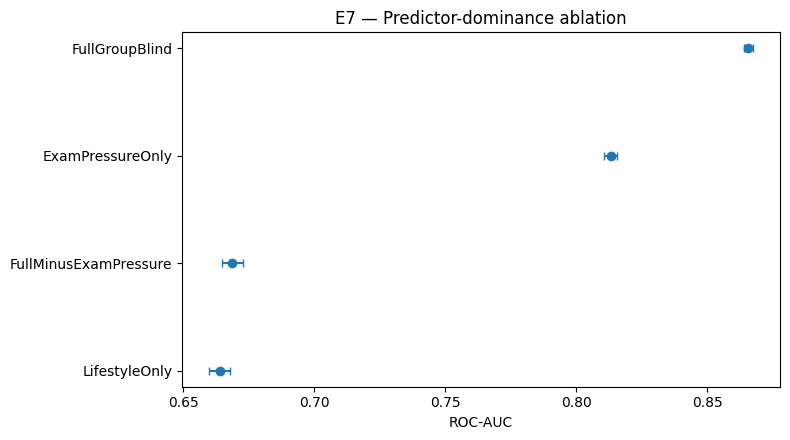

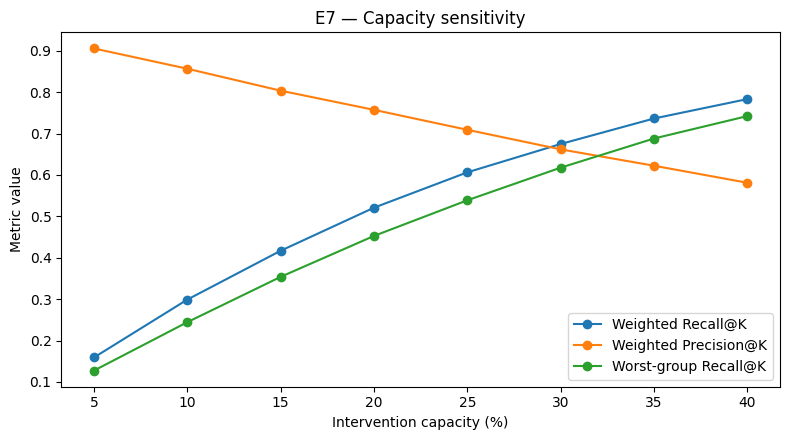

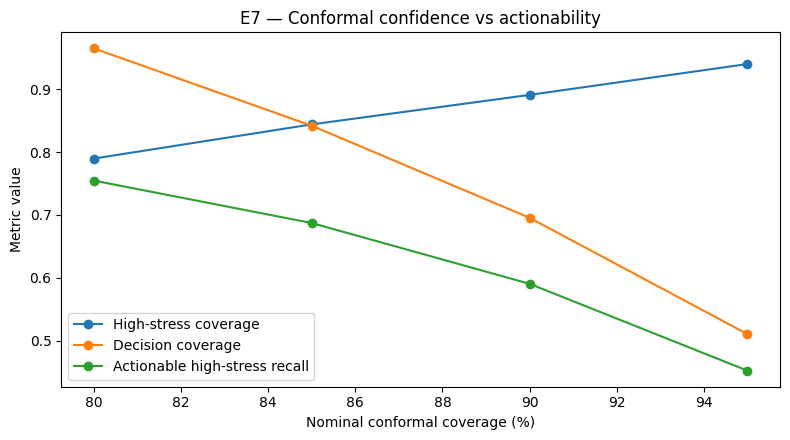

In [10]:

# Figure A — Predictor dominance (ROC-AUC with bootstrap CI)
auc_ab = ablation_summary[ablation_summary["metric"] == "roc_auc"].copy()
auc_ab = auc_ab.sort_values("mean", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
xerr = np.vstack([
    auc_ab["mean"] - auc_ab["bootstrap95_low"],
    auc_ab["bootstrap95_high"] - auc_ab["mean"],
])
ax.errorbar(
    auc_ab["mean"],
    np.arange(len(auc_ab)),
    xerr=xerr,
    fmt="o",
    capsize=3,
)
ax.set_yticks(np.arange(len(auc_ab)))
ax.set_yticklabels(auc_ab["feature_set"])
ax.set_xlabel("ROC-AUC")
ax.set_title("E7 — Predictor-dominance ablation")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "Fig_A_Predictor_Dominance_AUC.png",
    dpi=250, bbox_inches="tight"
)
plt.show()

# Figure B — Extended capacity curve
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    cap_summary["capacity"]*100,
    cap_summary["recall_mean"],
    marker="o",
    label="Weighted Recall@K",
)
ax.plot(
    cap_summary["capacity"]*100,
    cap_summary["precision_mean"],
    marker="o",
    label="Weighted Precision@K",
)
ax.plot(
    cap_summary["capacity"]*100,
    cap_summary["recall_worst_group"],
    marker="o",
    label="Worst-group Recall@K",
)
ax.set_xlabel("Intervention capacity (%)")
ax.set_ylabel("Metric value")
ax.set_title("E7 — Capacity sensitivity")
ax.legend()
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "Fig_B_Capacity_Sensitivity.png",
    dpi=250, bbox_inches="tight"
)
plt.show()

# Figure C — Conformal alpha trade-off
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    alpha_summary["nominal_coverage"]*100,
    alpha_summary["coverage_high"],
    marker="o",
    label="High-stress coverage",
)
ax.plot(
    alpha_summary["nominal_coverage"]*100,
    alpha_summary["decision_coverage"],
    marker="o",
    label="Decision coverage",
)
ax.plot(
    alpha_summary["nominal_coverage"]*100,
    alpha_summary["actionable_high_recall"],
    marker="o",
    label="Actionable high-stress recall",
)
ax.set_xlabel("Nominal conformal coverage (%)")
ax.set_ylabel("Metric value")
ax.set_title("E7 — Conformal confidence vs actionability")
ax.legend()
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "Fig_C_Conformal_Alpha_Sensitivity.png",
    dpi=250, bbox_inches="tight"
)
plt.show()



# E7 Decision Gate — Freeze the experimental code

The experimental program is considered sufficiently mature for manuscript preparation if the following hold:

1. **Seed sensitivity is small** relative to the main E1/E2 effects.
2. **Plausibility correction does not materially change conclusions**.
3. `Exam_Pressure` dominance remains evident under repeated CV.
4. Mondrian conformal consistently improves high-stress coverage relative to marginal conformal.
5. Capacity curves show the expected precision–recall trade-off without qualitative instability.
6. No new model is required to explain the central result.

## Recommended manuscript claim hierarchy

### Primary claim
Reliable student-stress screening requires separating:
- discrimination,
- probability calibration,
- uncertainty quantification,
- decision thresholds,
- intervention capacity.

### Secondary claim
Under LOSO population shift, score ranking transfers more robustly than decision and uncertainty policies.

### Operational claim
At fixed capacity, risk ranking is the most efficient prioritization mechanism observed here; conformal inference contributes confidence/abstention semantics rather than a superior ranking.

### Important limitation
The public benchmark is simulated/synthetic-like and cannot support causal or clinical claims. External validation on real institutional data would materially strengthen the study.


In [11]:

manifest = {
    "experiment": "E7 Robustness, Statistical Inference, and Publication Synthesis",
    "dataset_rows": int(len(df)),
    "seed_sensitivity_seeds": SEEDS,
    "ablation_sets": list(ABLATIONS.keys()),
    "data_quality_versions": list(quality_versions.keys()),
    "extended_capacities": EXTENDED_K,
    "conformal_alpha_grid": ALPHA_GRID,
    "bootstrap_iterations": 5000,
    "paired_test": "Wilcoxon signed-rank on paired resampling units where appropriate",
    "seed": SEED,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
}

with open(
    RESULT_DIR / "run_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

print("Saved E7 outputs:")
for p in sorted(RESULT_DIR.glob("*")):
    print("-", p)


Saved E7 outputs:
- student_stress_e7_outputs/Fig_A_Predictor_Dominance_AUC.png
- student_stress_e7_outputs/Fig_B_Capacity_Sensitivity.png
- student_stress_e7_outputs/Fig_C_Conformal_Alpha_Sensitivity.png
- student_stress_e7_outputs/Table1_Dataset_Audit.csv
- student_stress_e7_outputs/Table2A_IID.csv
- student_stress_e7_outputs/Table2B_LOSO.csv
- student_stress_e7_outputs/Table3_Calibration_LOSO.csv
- student_stress_e7_outputs/Table4_Threshold_and_GroupDRO.csv
- student_stress_e7_outputs/Table5_Conformal_Uncertainty.csv
- student_stress_e7_outputs/Table6_Capacity_Policy.csv
- student_stress_e7_outputs/e7_conformal_alpha_by_repeat.csv
- student_stress_e7_outputs/e7_conformal_alpha_summary.csv
- student_stress_e7_outputs/e7_data_quality_sensitivity_by_split.csv
- student_stress_e7_outputs/e7_data_quality_sensitivity_summary.csv
- student_stress_e7_outputs/e7_extended_capacity_by_repeat.csv
- student_stress_e7_outputs/e7_extended_capacity_summary.csv
- student_stress_e7_outputs/e7_paired_